<a href="https://colab.research.google.com/github/CSE-Mashal/svd-image-compression/blob/main/notebooks/03_measuring_compression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import os
import subprocess
import sys

USER = "CSE-Mashal"
REPO = "svd-image-compression"

if os.path.exists(REPO):
    subprocess.run(["git", "-C", REPO, "pull"], check=True)
else:
    subprocess.run(
        ["git", "clone", f"https://github.com/{USER}/{REPO}.git", REPO],
        check=True)

sys.path.insert(0, f"{REPO}/src")
from compress import rank_k_approx

I load the rank-k function from our GitHub repository so I can use it again.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import data

A = data.camera().astype(float)
m, n = A.shape
T = data.text().astype(float)
print("Camera:", A.shape, "Text:", T.shape)

Camera: (512, 512) Text: (172, 448)


I load the camera and text images. I change them to float for the SVD calculations.

In [3]:
def storage(m, n, k):
    return k * (m + n + 1)

def compression_ratio(m, n, k):
    return (m * n) / storage(m, n, k)

print("Original camera values:", m * n)
for k in [1, 10, 50, 100, 255, 256]:
    print(f"k={k:3d} stored={storage(m, n, k):6d} "
          f"ratio={compression_ratio(m, n, k):.2f}")

Original camera values: 262144
k=  1 stored=  1025 ratio=255.75
k= 10 stored= 10250 ratio=25.58
k= 50 stored= 51250 ratio=5.12
k=100 stored=102500 ratio=2.56
k=255 stored=261375 ratio=1.00
k=256 stored=262400 ratio=1.00


These functions count the stored values and find the compression ratio. A ratio above 1 means fewer values are stored. For the camera image, rank 256 stops saving values.

In [4]:
def rel_error(A, B):
    return np.linalg.norm(A - B) / np.linalg.norm(A)

for k in [1, 5, 20, 50, 100]:
    Ak = rank_k_approx(A, k)
    print(f"k={k:3d} relative error={rel_error(A, Ak):.4f}")

k=  1 relative error=0.3604
k=  5 relative error=0.1720
k= 20 relative error=0.1012
k= 50 relative error=0.0636
k=100 relative error=0.0393


This measures how different the approximation is from the original. Using a larger rank makes the error smaller.

In [5]:
U, s, Vt = np.linalg.svd(A, full_matrices=False)

def predicted_error(s, k):
    return np.sqrt(np.sum(s[k:]**2) / np.sum(s**2))

for k in [1, 5, 20, 50, 100]:
    actual = rel_error(A, rank_k_approx(A, k))
    predicted = predicted_error(s, k)
    print(f"k={k:3d} actual={actual:.6f} predicted={predicted:.6f}")

k=  1 actual=0.360449 predicted=0.360449
k=  5 actual=0.172014 predicted=0.172014
k= 20 actual=0.101208 predicted=0.101208
k= 50 actual=0.063565 predicted=0.063565
k=100 actual=0.039329 predicted=0.039329


The singular values left out tell us the error. The actual and predicted errors should match. The slice s[k:] starts with the first singular value we did not keep.

In [6]:
ks = np.arange(1, len(s) + 1)
errors = np.array([predicted_error(s, k) for k in ks])
for target in [0.10, 0.05, 0.02, 0.01]:
    k = ks[errors <= target][0]
    ratio = compression_ratio(m, n, k)
    print(f"target={target:.0%}, k={k}, ratio={ratio:.2f}")

target=10%, k=21, ratio=12.18
target=5%, k=73, ratio=3.50
target=2%, k=186, ratio=1.38
target=1%, k=263, ratio=0.97


I find the smallest rank that meets each target error. A smaller target needs more terms, so it saves fewer values.

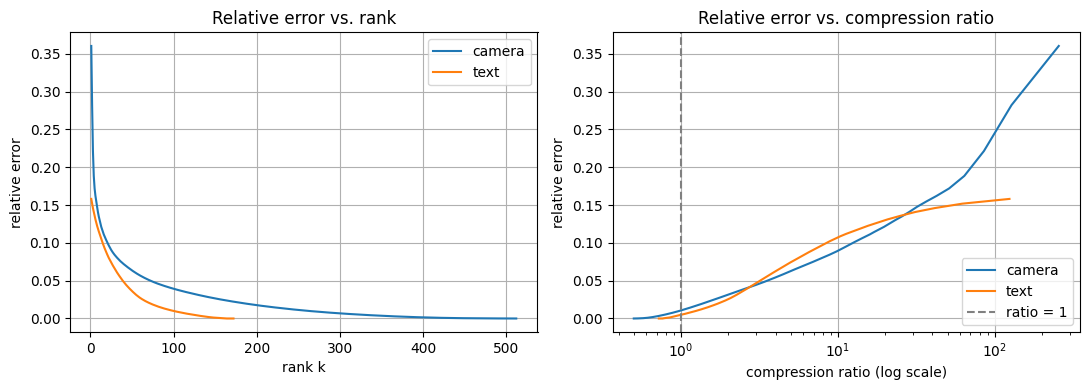

In [7]:
images = {"camera": A, "text": T}
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
for name, M in images.items():
    m_img, n_img = M.shape
    s_img = np.linalg.svd(M, compute_uv=False)
    ranks = np.arange(1, len(s_img) + 1)
    errs = [predicted_error(s_img, k) for k in ranks]
    ratios = [compression_ratio(m_img, n_img, k) for k in ranks]
    ax1.plot(ranks, errs, label=name)
    ax2.semilogx(ratios, errs, label=name)
ax1.set_title("Relative error vs. rank")
ax1.set_xlabel("rank k")
ax1.set_ylabel("relative error")
ax2.axvline(1, color="gray", linestyle="--", label="ratio = 1")
ax2.set_title("Relative error vs. compression ratio")
ax2.set_xlabel("compression ratio (log scale)")
ax2.set_ylabel("relative error")
for ax in (ax1, ax2):
    ax.grid()
    ax.legend()
plt.tight_layout()
plt.savefig(f"{REPO}/figures/error_vs_ratio.png", dpi=150)
plt.show()

I compare the error and compression ratio for both images. The line at ratio 1 marks where the factors stop saving values. I save this plot in the figures folder.

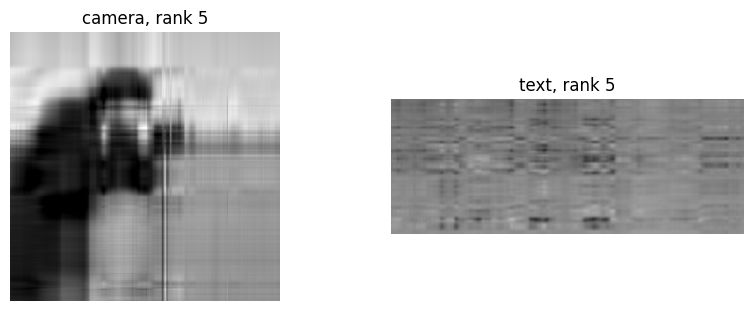

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for ax, (name, M) in zip(axes, images.items()):
    Mk = np.clip(rank_k_approx(M, 5), 0, 255)
    ax.imshow(Mk, cmap="gray", vmin=0, vmax=255)
    ax.set_title(f"{name}, rank 5")
    ax.axis("off")
plt.show()

I look at both rank-5 images. The text can be hard to read even if its error is small.

In [9]:
A20 = rank_k_approx(A, 20)
outside = (A20 < 0) | (A20 > 255)
print("Out-of-range pixels:", outside.sum())
print("Fraction:", f"{outside.mean():.1%}")
print("Error before clipping:", round(rel_error(A, A20), 4))
print("Error after clipping:",
      round(rel_error(A, np.clip(A20, 0, 255)), 4))

Out-of-range pixels: 2634
Fraction: 1.0%
Error before clipping: 0.1012
Error after clipping: 0.1008


Clipping keeps pixel values between 0 and 255. Since the original pixels are in this range, clipping cannot increase the error.

In [10]:
from google.colab import files
from PIL import Image

uploaded = files.upload()
name = list(uploaded)[0]
P = np.array(Image.open(name).convert("L"))
print("Photo shape:", P.shape)

Saving download (4).png to download (4).png
Photo shape: (366, 241)


I upload our grayscale photo and turn it into a matrix. I use the smaller grayscale copy of our Milestone 1 photo.

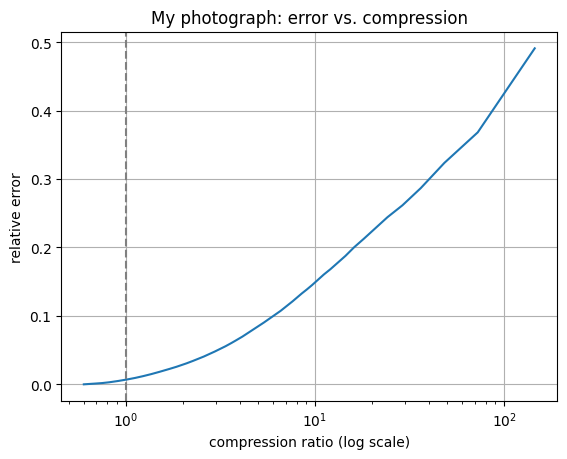

In [11]:
P_float = P.astype(float)
sp = np.linalg.svd(P_float, compute_uv=False)
kp = np.arange(1, len(sp) + 1)
ep = [predicted_error(sp, k) for k in kp]
mp, npix = P_float.shape
rp = [compression_ratio(mp, npix, k) for k in kp]

plt.semilogx(rp, ep)
plt.axvline(1, color="gray", linestyle="--")
plt.xlabel("compression ratio (log scale)")
plt.ylabel("relative error")
plt.title("My photograph: error vs. compression")
plt.grid()
plt.show()

I change the photo to float and plot its error against its compression ratio. Saving more values usually gives a smaller error.

Rank: 30
Relative error: 0.0819
Stored values: 18240
Compression ratio: 4.84


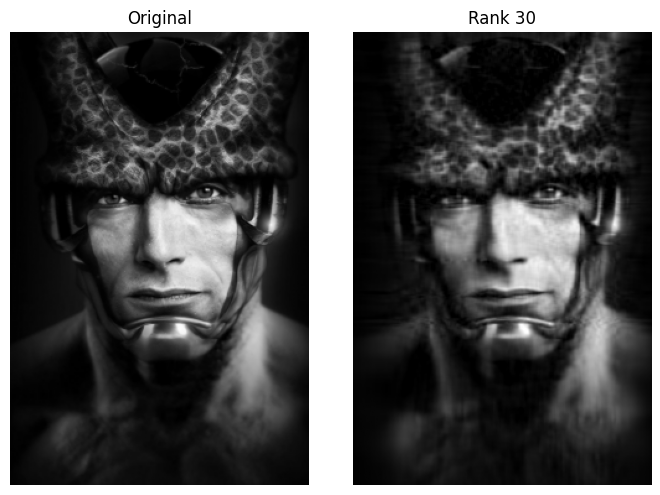

In [12]:
k = 30
Pk = rank_k_approx(P_float, k)
print("Rank:", k)
print("Relative error:", round(rel_error(P_float, Pk), 4))
print("Stored values:", storage(mp, npix, k))
print("Compression ratio:", round(compression_ratio(mp, npix, k), 2))

fig, axes = plt.subplots(1, 2, figsize=(7, 5))
axes[0].imshow(P, cmap="gray", vmin=0, vmax=255)
axes[0].set_title("Original")
axes[1].imshow(np.clip(Pk, 0, 255), cmap="gray", vmin=0, vmax=255)
axes[1].set_title("Rank 30")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

I choose rank 30. The error is about 8.19%, and it stores about 4.84 times fewer values. The face and helmet are still recognizable, but some small details are lost.

## Exercise 1

To save values, we need $k(m+n+1)<mn$, so $k<mn/(m+n+1)$.

The largest whole number that works is $\lceil mn/(m+n+1)\rceil-1$. In Python, `(m*n - 1) // (m+n+1)` gives the same answer.

Each uint8 pixel uses 1 byte, but each float64 factor value uses 8 bytes. To save bytes, we need $8k(m+n+1)<mn$.

In [13]:
print("U dtype:", U.dtype)
print("Bytes per value:", U.itemsize)

for name, M in images.items():
    rows, cols = M.shape
    k_values = (rows * cols - 1) // (rows + cols + 1)
    k_bytes = (rows * cols - 1) // (U.itemsize * (rows + cols + 1))
    print(name)
    print("Largest rank saving values:", k_values)
    print("Stops saving values at rank:", k_values + 1)
    print("Largest rank saving bytes:", k_bytes)
    print("Stops saving bytes at rank:", k_bytes + 1)

U dtype: float64
Bytes per value: 8
camera
Largest rank saving values: 255
Stops saving values at rank: 256
Largest rank saving bytes: 31
Stops saving bytes at rank: 32
text
Largest rank saving values: 124
Stops saving values at rank: 125
Largest rank saving bytes: 15
Stops saving bytes at rank: 16


For the camera image, ranks up to 255 save values, but only ranks up to 31 save bytes. The text image uses the same rule with its own dimensions. Counting bytes is stricter because each factor value takes more space.

## Exercise 2

In [14]:
print("Norm squared:", np.linalg.norm(A)**2)
print("Sum of singular values squared:", np.sum(s**2))
print("Do they match?", np.isclose(np.linalg.norm(A)**2, np.sum(s**2)))

Norm squared: 5788200983.000001
Sum of singular values squared: 5788200983.0
Do they match? True


The two results are approximately equal. Eckart–Young says the squared error is the sum of the squared singular values we leave out. Dividing by the sum of all squared singular values and taking the square root gives the relative error.

## Exercise 3

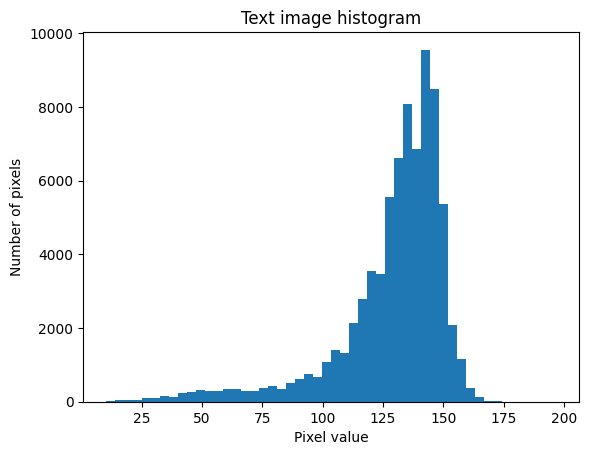

Most common pixel range: 140.9 to 144.6


In [15]:
plt.hist(T.ravel(), bins=50)
plt.xlabel("Pixel value")
plt.ylabel("Number of pixels")
plt.title("Text image histogram")
plt.show()

counts, bins = np.histogram(T.ravel(), bins=50)
i = np.argmax(counts)
print("Most common pixel range:", round(bins[i], 1), "to", round(bins[i + 1], 1))

Most pixels are around 140.9–144.6, which are gray background values. Matching the large background can give a small error even when the letters are blurry. I would also check how many words I can read correctly.


## Exercise 4

camera rank: 21 ratio: 12.18
text rank: 15 ratio: 8.27
our photo rank: 25 ratio: 5.8
Largest ratio at 10% error: camera


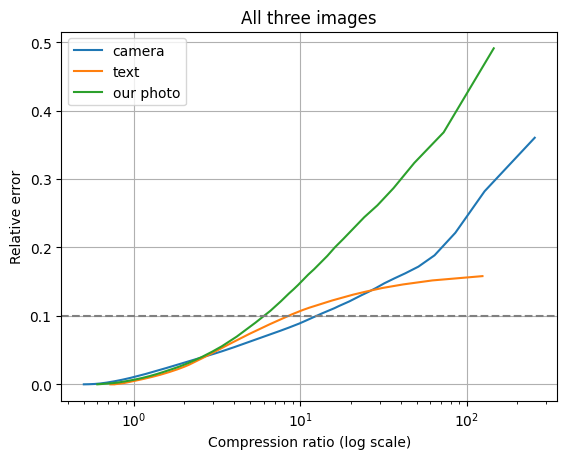

In [16]:
images_all = {"camera": A, "text": T, "our photo": P_float}
best_image = ""
best_ratio = 0

for name, M in images_all.items():
    rows, cols = M.shape
    si = np.linalg.svd(M, compute_uv=False)
    ranks = np.arange(1, len(si) + 1)
    errors = np.array([predicted_error(si, k) for k in ranks])
    ratios = [compression_ratio(rows, cols, k) for k in ranks]
    k = ranks[errors <= 0.10][0]
    ratio = compression_ratio(rows, cols, k)
    print(name, "rank:", k, "ratio:", round(ratio, 2))
    if ratio > best_ratio:
        best_image = name
        best_ratio = ratio
    plt.semilogx(ratios, errors, label=name)

print("Largest ratio at 10% error:", best_image)
plt.axhline(0.10, color="gray", linestyle="--")
plt.xlabel("Compression ratio (log scale)")
plt.ylabel("Relative error")
plt.title("All three images")
plt.legend()
plt.grid()
plt.show()

The camera image has the largest compression ratio at 10% error: 12.18 at rank 21. The text image has a ratio of 8.27, and our photo has a ratio of 5.80. The camera’s first 21 singular values keep enough information to meet the target while saving the most values compared with its original size.

## Exercise 5

Let $a$ be a true pixel between 0 and 255, and let $x$ be its approximation.

- If $x<0$, clipping changes it to 0. Its error becomes $a$, which is no larger than $a-x$.
- If $0\leq x\leq255$, clipping does not change it, so the error stays the same.
- If $x>255$, clipping changes it to 255. Its error becomes $255-a$, which is no larger than $x-a$.

So clipping cannot increase any pixel's absolute error. The Frobenius error squares all the pixel errors, adds them, and takes the square root. Since none of the pixel errors increases, the Frobenius error cannot increase either.

## Exercise 6

I would use rank 30. Its relative error is about 8.19%, and its compression ratio is about 4.84. In the Part H comparison, the face and helmet are still clear, but the original has more fine details.

This saves values, but float64 factors use more bytes than the original uint8 pixels at this rank.